In [1]:
import numpy as np
import pandas as pd
from scipy import sparse
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

## Распределение подструктур по кол-ву атомов в их составе.

In [2]:
unique_substructures_df = pd.read_pickle('../source_data/INIT_unique_substructures_Rcut_7.5_stephist_0.1.pkl')

In [3]:
sns.set_theme(style="whitegrid")

In [4]:
unique_substructures_df.head()

,Structure,Num_atoms,CN
0,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",18,"[4.0, 1.0, 4.0, 4.0, 4.0, 0.0, 0.0]"
1,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",46,"[6.0, 3.0, 9.0, 4.0, 9.0, 2.0, 12.0]"
2,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",46,"[8.0, 5.0, 12.0, 4.0, 4.0, 4.0, 8.0]"
3,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",46,"[5.0, 3.0, 9.0, 3.0, 8.0, 3.0, 14.0]"
4,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",46,"[5.0, 3.0, 8.0, 5.0, 6.0, 4.0, 14.0]"


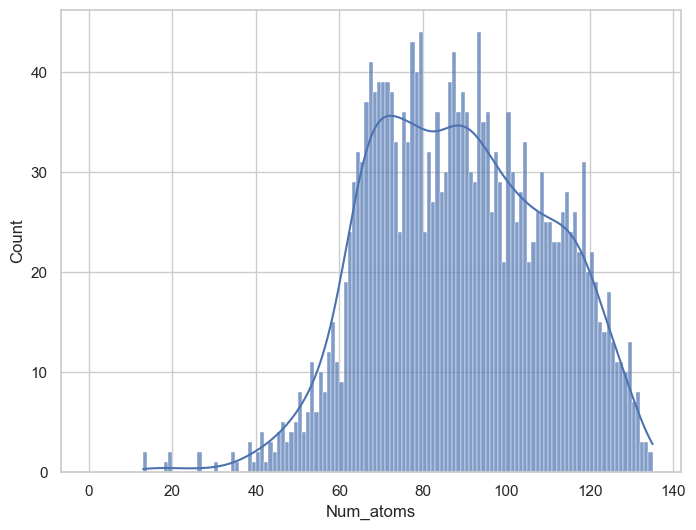

In [5]:
plt.figure(figsize=(8,6))
sns.histplot(data=unique_substructures_df,
             x='Num_atoms',
             bins=range(0,136,1),
             stat='count',
             kde=True,
             alpha=0.7,
            )
plt.savefig('../images/Substructures_distrib_by_n_atoms.png',dpi=600)
plt.show()

In [6]:
unique_by_n_atoms, counts_for_unique = np.unique(unique_substructures_df.Num_atoms.values,return_counts=True)
print(unique_by_n_atoms,'\n',counts_for_unique)

# Видно что при вырезании кластера с радиусом 7.5 наибольшее кол-во атомов в составе подструктуры равно 135
# Соответствующая подструктура с точки зрения расчета должна быть наиболее всего приближена к объемному образцу фольги.
# Соответствующая подструктура находится под номером 2045
unique_substructures_df.query('Num_atoms==135')

[ 13  18  19  26  30  34  35  38  39  40  41  42  43  44  45  46  47  48
  49  50  51  52  53  54  55  56  57  58  59  60  61  62  63  64  65  66
  67  68  69  70  71  72  73  74  75  76  77  78  79  80  81  82  83  84
  85  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100 101 102
 103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120
 121 122 123 124 125 126 127 128 129 130 131 132 133 134 135] 
 [ 2  1  2  2  1  2  1  3  1  2  4  1  3  2  4  5  3  4  5  8  4  6 11  6
 10  8 12 15 11  9 19 24 29 32 31 37 41 38 39 39 39 38 33 24 36 33 43 40
 44 24 32 27 36 28 30 39 42 36 38 36 30 29 44 35 36 26 32 29 21 36 30 25
 28 33 21 23 26 30 25 25 23 23 26 28 24 26 22 31 20 22 19 15 14 18 13 11
 11 10 13  7  8  3  3  1  1]


,Structure,Num_atoms,CN
2045,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",135,"[12.0, 6.0, 24.0, 12.0, 24.0, 8.0, 48.0]"


## Сопоставление спектров Pt foil

In [7]:
foil_spectrum_exp = np.loadtxt('../source_data/PtL3_foil.txt')
foil_spectrum_without_smearing = np.loadtxt("../source_data/Unique_Spectra/2045/Pt.txt",skiprows=2)
foil_spectrum_conv = np.loadtxt("../source_data/Unique_Spectra/2045/Pt_convolution.txt")

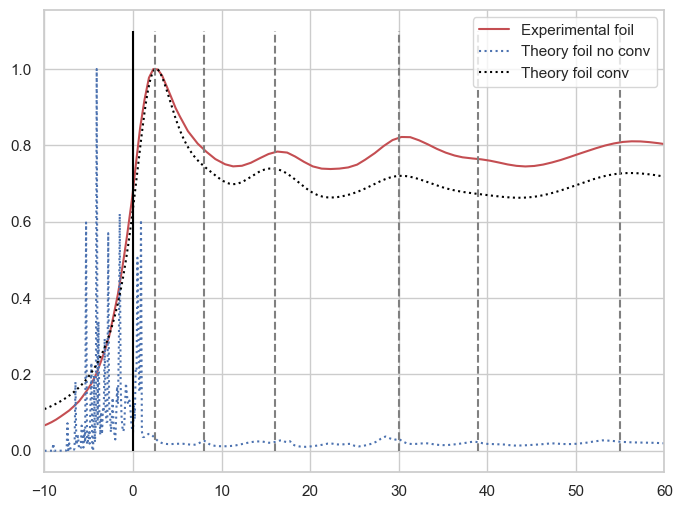

In [8]:
L3_edge = 11563

mask = (foil_spectrum_exp[:,0]>L3_edge-10)&(foil_spectrum_exp[:,0]<L3_edge+100)
foil_spectrum_exp_x_shifted = foil_spectrum_exp[:,0][mask]-L3_edge-1.7

plt.figure(figsize=(8,6))
plt.plot(foil_spectrum_exp_x_shifted, foil_spectrum_exp[:,1][mask]/foil_spectrum_exp[:,1][mask].max(),'r-', label='Experimental foil')
plt.plot(foil_spectrum_without_smearing[:,0],foil_spectrum_without_smearing[:,1]/foil_spectrum_without_smearing[:,1].max(),'b:', label='Theory foil no conv')
plt.plot(foil_spectrum_conv[:,0],foil_spectrum_conv[:,1]/foil_spectrum_conv[:,1].max(),color='black',ls=':', label='Theory foil conv')
plt.vlines(x=[2.5,8,16,30,39,55],ymin=0,ymax=1.1,colors='gray',ls='--')
plt.vlines(x=[0],ymin=0,ymax=1.1,colors='black')
plt.xlim(-10,60)
plt.legend()

plt.savefig('../images/Foil_comparison.png', dpi=600)

plt.show()

## Рассмотрение неразмазанных спектров для подструктур разного размера (кол-ва атомов в составе).

In [9]:
SPECTRA_ROOT = Path('../source_data/Unique_Spectra/')

SPECTRA_PATH_LIST_not_conv = list(SPECTRA_ROOT.glob('*/Pt.txt'))
SORTED_SPECTRA_PATH_LIST_not_conv = sorted(SPECTRA_PATH_LIST_not_conv, key=lambda x: int(x.parent.name))

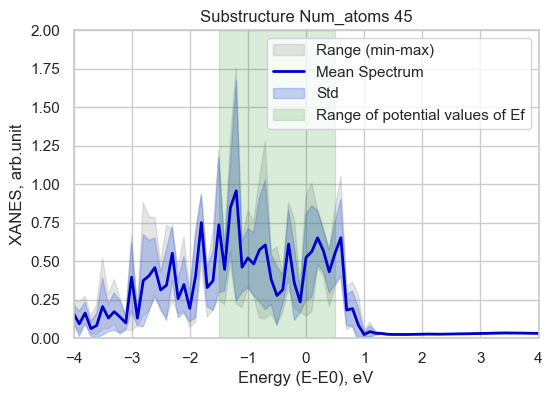

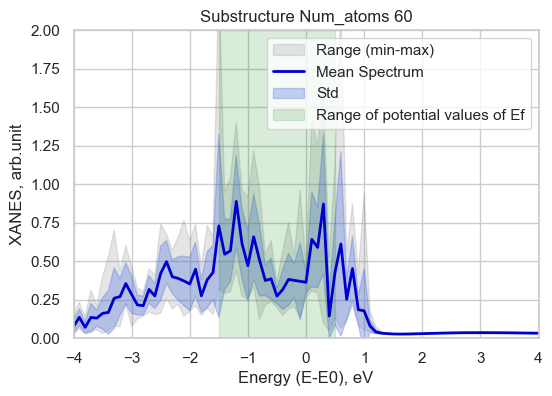

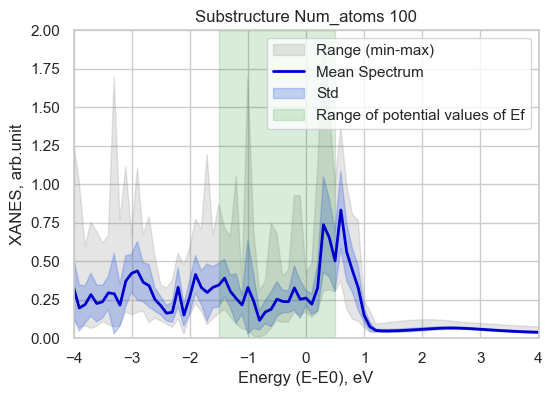

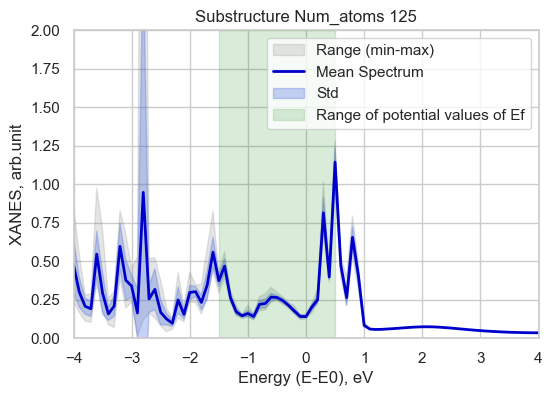

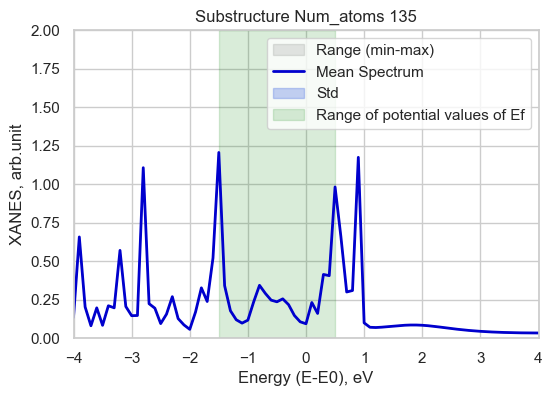

In [10]:
num_atoms_list = [45, 60, 100, 125, 135]

for n_a in num_atoms_list:
    tdf = unique_substructures_df.query(f'Num_atoms == {n_a}').copy()
    spectra_indecies = tdf.index.values
    spectra_sublist = [np.loadtxt(SORTED_SPECTRA_PATH_LIST_not_conv[ind],skiprows=2) for ind in spectra_indecies]
    
    x_axis = spectra_sublist[0][:, 0]
    all_y = np.array([spec[:, 1] for spec in spectra_sublist])


    mean_y = np.mean(all_y, axis=0)
    min_y = np.min(all_y, axis=0)
    max_y = np.max(all_y, axis=0)

    std_y = np.std(all_y, axis=0)
    lower_bound = mean_y - std_y
    upper_bound = mean_y + std_y

    plt.figure(figsize=(6,4))
    plt.title(f'Substructure Num_atoms {n_a}')

    plt.fill_between(x_axis, min_y, max_y, color='gray', alpha=0.2, label='Range (min-max)')
    
    plt.plot(x_axis, mean_y, color='mediumblue', linewidth=2, label='Mean Spectrum')

    plt.fill_between(x_axis, lower_bound, upper_bound, color='royalblue', alpha=0.3, label='Std')
    
    plt.axvspan(-1.5, 0.5, color='green', alpha=0.15, label='Range of potential values of Ef')
    
    plt.ylim(0,2)
    plt.xlim(-4,4)
    
    plt.xlabel('Energy (E-E0), eV')
    plt.ylabel('XANES, arb.unit')
    plt.legend()
    plt.savefig(f'../images/XANES_Pre_edge_Sub_NA_{n_a}.png',dpi=600)
    plt.show()  

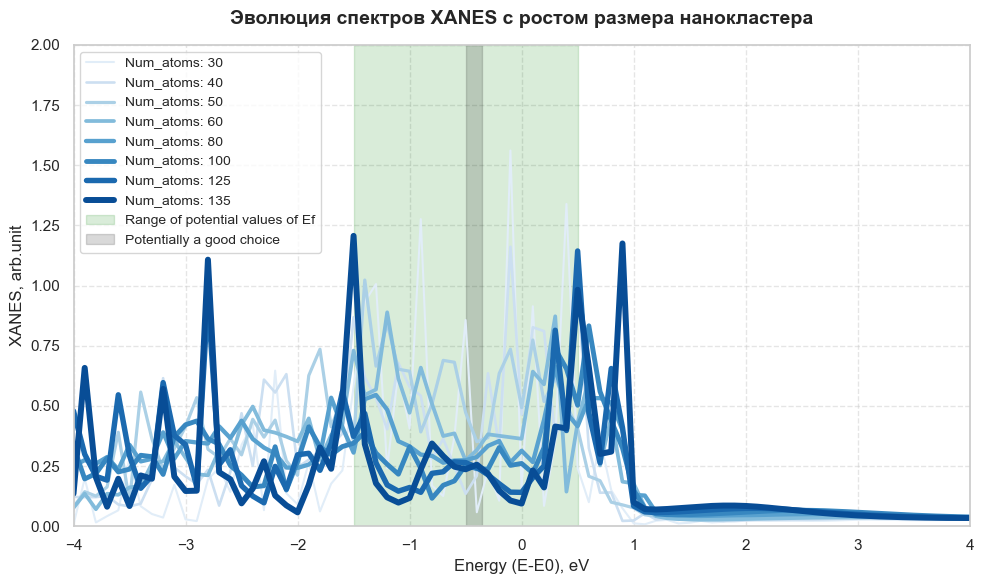

In [11]:
num_atoms_list = [30,40,50,60, 80, 100, 125, 135]

plt.figure(figsize=(10, 6))

# Создаем последовательный градиент цвета (от мелких к крупным НК)
colors = sns.color_palette("Blues", len(num_atoms_list))

for i, n_a in enumerate(num_atoms_list):
    tdf = unique_substructures_df.query(f'Num_atoms == {n_a}').copy()
    spectra_indecies = tdf.index.values
    
    spectra_sublist = [np.loadtxt(SORTED_SPECTRA_PATH_LIST_not_conv[ind], skiprows=2) for ind in spectra_indecies]
    
    x_axis = spectra_sublist[0][:, 0]
    all_y = np.array([spec[:, 1] for spec in spectra_sublist])
    
    mean_y = np.mean(all_y, axis=0)
    
    line_width = 1.5 + (i * 0.4) 
    
    plt.plot(x_axis, mean_y, color=colors[i], linewidth=line_width, label=f'Num_atoms: {n_a}')

# axvspan - вертикальной полосы во всю высоту графика
plt.axvspan(-1.5, 0.5, color='green', alpha=0.15, label='Range of potential values of Ef')
plt.axvspan(-.5, -0.35, color='black', alpha=0.15, label='Potentially a good choice')

plt.title('Эволюция спектров XANES с ростом размера нанокластера', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Energy (E-E0), eV', fontsize=12)
plt.ylabel('XANES, arb.unit', fontsize=12)

plt.ylim(0, 2)
plt.xlim(-4, 4)

plt.legend(loc='upper left', fontsize=10, frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig('../images/XANES_size_Pre_edge_dependence.png', dpi=600)
    
plt.show()

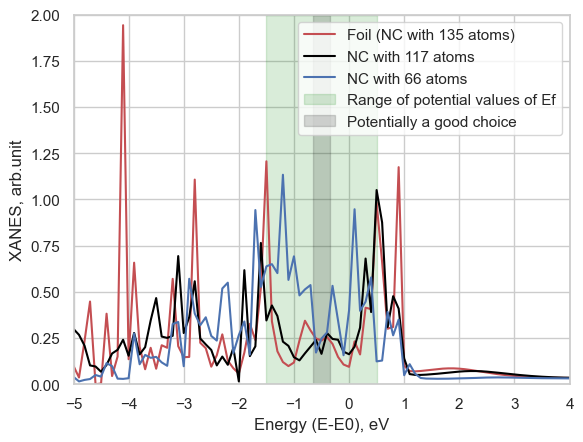

In [12]:
spectrum_2045 = np.loadtxt(SORTED_SPECTRA_PATH_LIST_not_conv[2045],skiprows=2) # 135 атомов
spectrum_100 = np.loadtxt(SORTED_SPECTRA_PATH_LIST_not_conv[100],skiprows=2) # 66 атомов
spectrum_2100 = np.loadtxt(SORTED_SPECTRA_PATH_LIST_not_conv[2100],skiprows=2) # 117 атомов

plt.figure()
plt.plot(spectrum_2045[:,0],spectrum_2045[:,1],'r-',label='Foil (NC with 135 atoms)')
plt.plot(spectrum_2100[:,0],spectrum_2100[:,1],color='black',label='NC with 117 atoms')
plt.plot(spectrum_100[:,0],spectrum_100[:,1],'b-',label='NC with 66 atoms')

plt.axvspan(-1.5, 0.5, color='green', alpha=0.15, label='Range of potential values of Ef')
plt.axvspan(-.65, -0.35, color='black', alpha=0.15, label='Potentially a good choice')

plt.ylim(0,2)
plt.legend()
plt.xlim(-5,4)
plt.xlabel('Energy (E-E0), eV')
plt.ylabel('XANES, arb.unit')

plt.savefig('../images/Edge_graph_example.png')

plt.show()

## Базовая демонстрация влияния частоты дескритизации

In [13]:
from scipy.ndimage import gaussian_filter1d
from typing import Union

def discretization_influence(step=0.25, shift=0.0, save_path:Union[Path,str]=None):
    """   
    Args:
        step (float): Шаг дискретизации грубой сетки в эВ.
        shift (float): Сдвиг грубой сетки в эВ.
    """
    e_min, e_max = -2.0, 10.0
    true_resolution = 10000  
    sigma_smearing = 0.4    # Ширина экспериментального уширения
    peak_width = 0.03       # ширина расчетных пиков НК

    x_fine = np.linspace(e_min, e_max, true_resolution)
    
    # Грубая сетка от e_min + shift с заданным шагом step
    x_coarse = np.arange(e_min + shift, e_max, step)
    
    # Модельный спектр
    def get_spectrum(x):
        peaks = [0.6, 1.2, 1.8, 4.2, 7.2]
        intensities = [1.0, 0.8, 0.9, 0.5, 0.3]
        y = np.zeros_like(x)
        for p, i in zip(peaks, intensities):
            y += i * np.exp(-((x - p)**2) / (2 * peak_width**2))
        return y

    y_fine_raw = get_spectrum(x_fine)
    y_coarse_raw = get_spectrum(x_coarse)

    # Размазка (Broadening/Convolution)
    
    dx_fine = (e_max - e_min) / (true_resolution - 1)
    dx_coarse = step
    
    # "Реальный" спектр
    y_fine_smeared = gaussian_filter1d(y_fine_raw, sigma_smearing / dx_fine, mode='constant')
    # Спектр, рассчитанный на грубой сетке
    y_coarse_smeared = gaussian_filter1d(y_coarse_raw, sigma_smearing / dx_coarse, mode='constant')

    # Сравнение интегралов
    int_fine = np.trapezoid(y_fine_smeared, x_fine)
    int_coarse = np.trapezoid(y_coarse_smeared, x_coarse)
    
    error_percent = (int_coarse / int_fine - 1) * 100
    error_type = "ЗАВЫШЕНИЕ" if error_percent > 0 else "ЗАНИЖЕНИЕ"

    # Визуализация
    plt.figure(figsize=(14, 7))
    plt.subplots_adjust(top=0.85)
    
    plt.suptitle(f"XANES Алиасинг: Step = {step} eV | Shift = {shift} eV", fontsize=15)

    # Левый - до размазки
    plt.subplot(1, 2, 1)
    plt.plot(x_fine, y_fine_raw, label='"Истинные" узкие пики (Reference)', color='blue', alpha=0.2, lw=1)
    
    # Отображаем точки сэмплирования
    plt.scatter(x_coarse, y_coarse_raw, color='red', s=3, label='Редкая сетка')
    
    plt.title("До размазки: Сэмплирование точек")
    plt.xlabel("Энергия (eV)")
    plt.ylabel("Интенсивность")
    plt.xlim(e_min, e_max)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)

    # Правый - после размазки
    plt.subplot(1, 2, 2)
    plt.plot(x_fine, y_fine_smeared, label='Корректный спектр (Плотная сетка)', color='blue', lw=2.5)
    plt.plot(x_coarse, y_coarse_smeared, label='Искаженный спектр (Грубая сетка)', color='red', linestyle='--', lw=2)
    
    plt.fill_between(x_fine, y_fine_smeared, color='blue', alpha=0.1)
    plt.fill_between(x_coarse, y_coarse_smeared, color='red', alpha=0.15)
    
    # Текст с ошибкой
    text_color = 'darkred' if error_percent > 0 else 'darkblue'
    plt.text(0.7, 0.7, f"Ошибка интеграла: {error_percent:+.1f}%\n({error_type})", 
             horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes,
             fontsize=12, color=text_color, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))

    plt.title("После размазки: Результат для XANES")
    plt.xlabel("Энергия (eV)")
    plt.ylabel("Интенсивность")
    plt.xlim(e_min, e_max)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)

    if save_path:
        plt.savefig(save_path, dpi=600)

    plt.show()

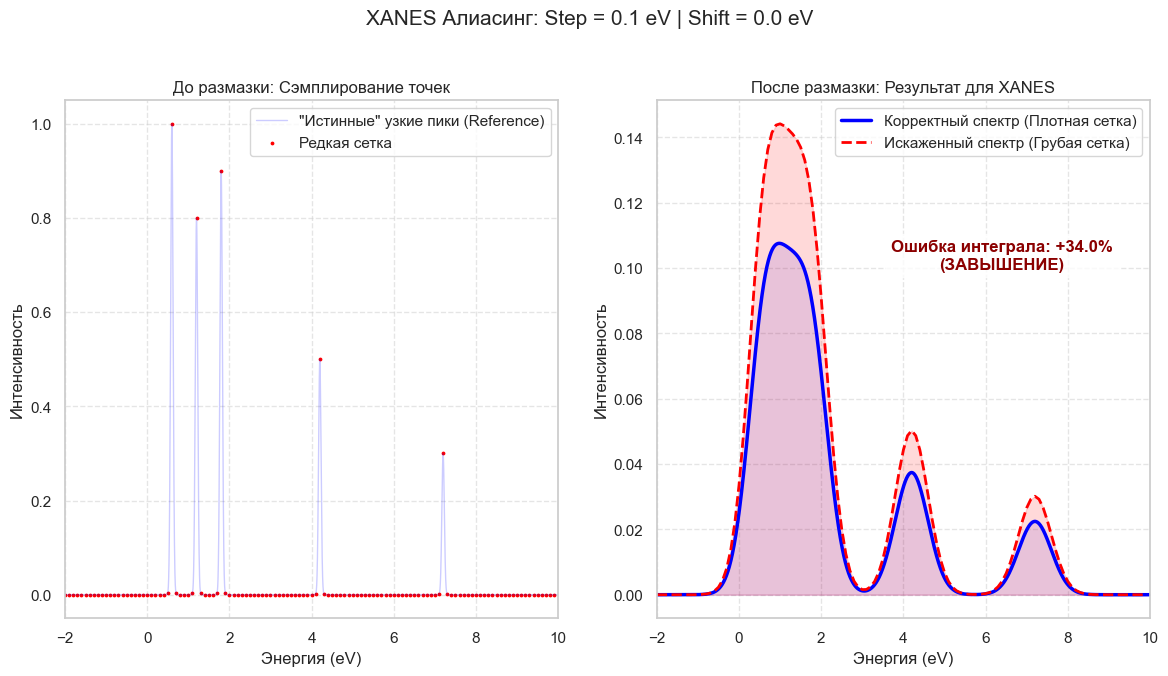

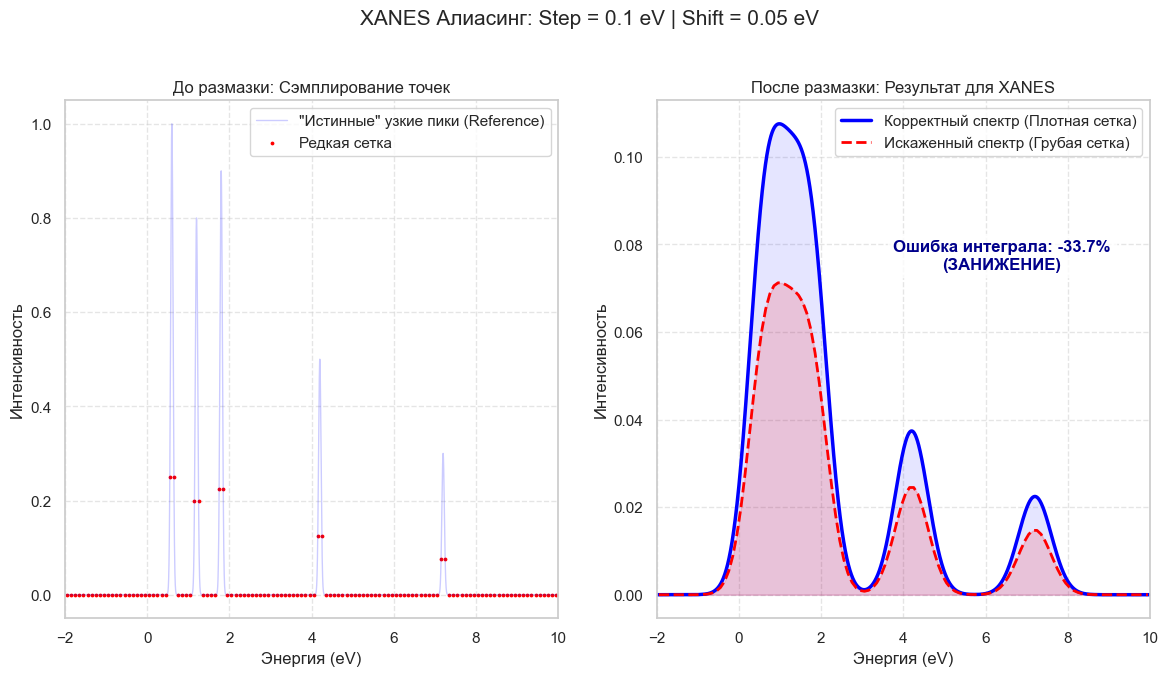

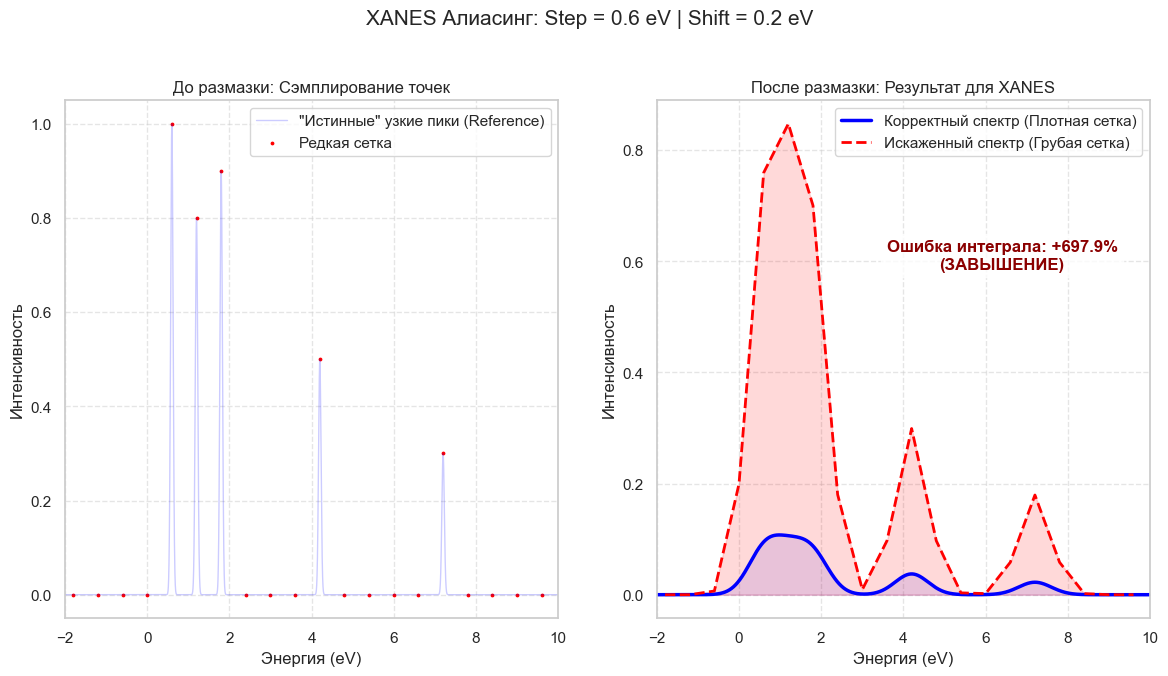

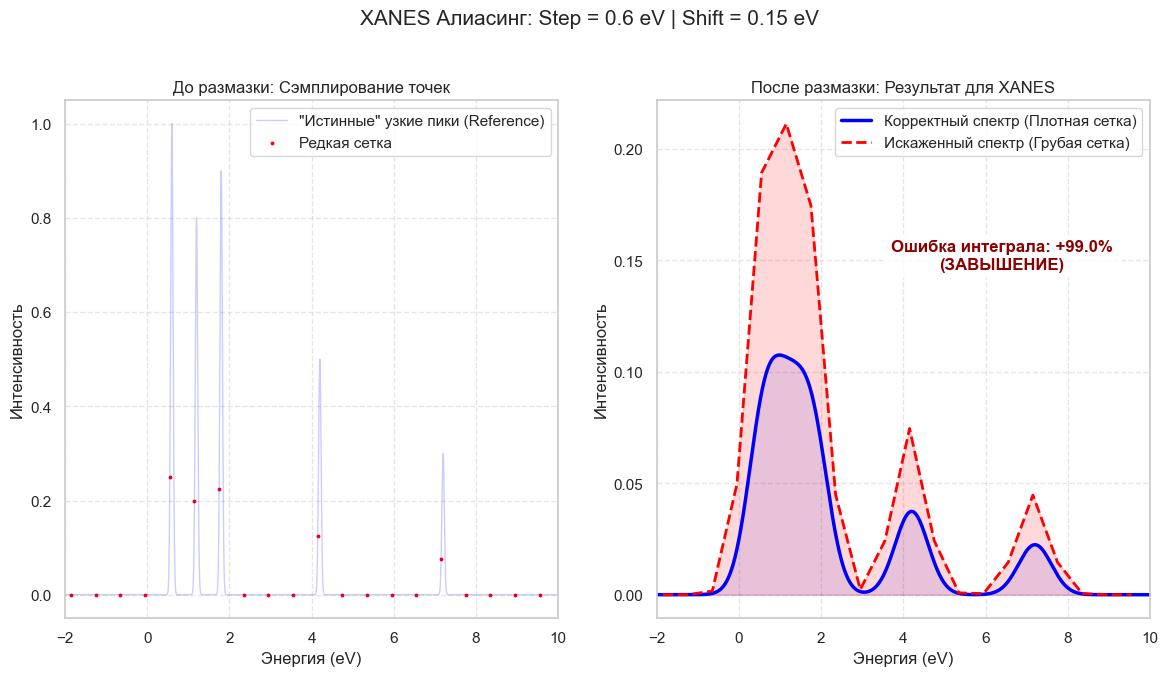

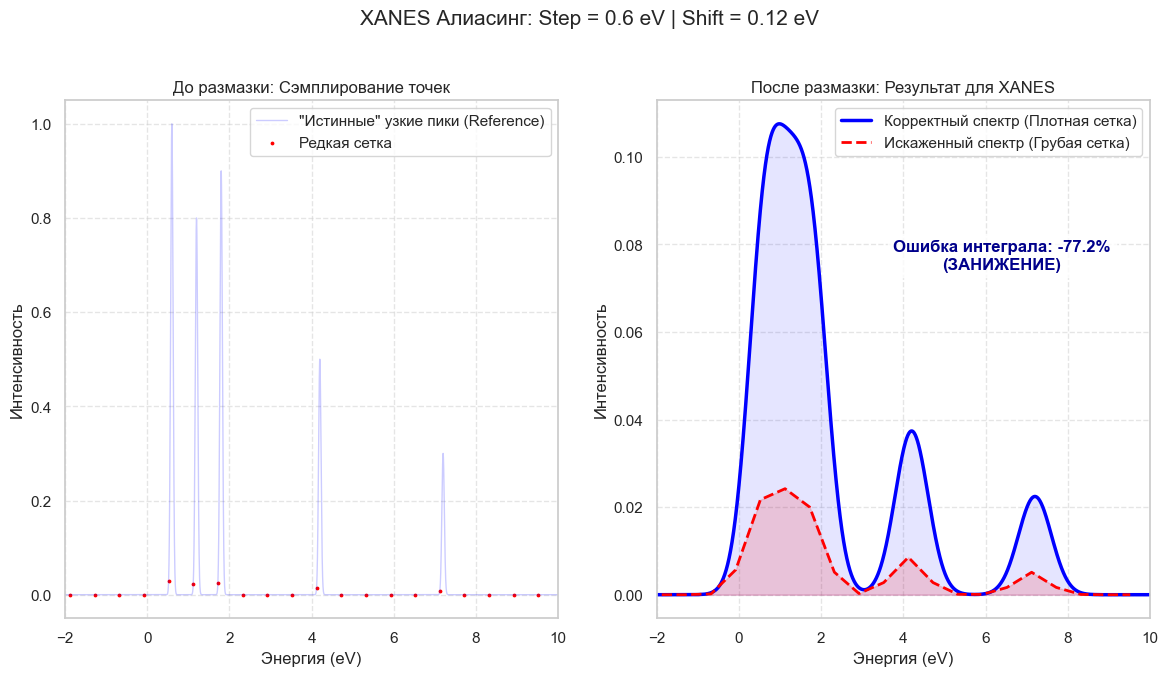

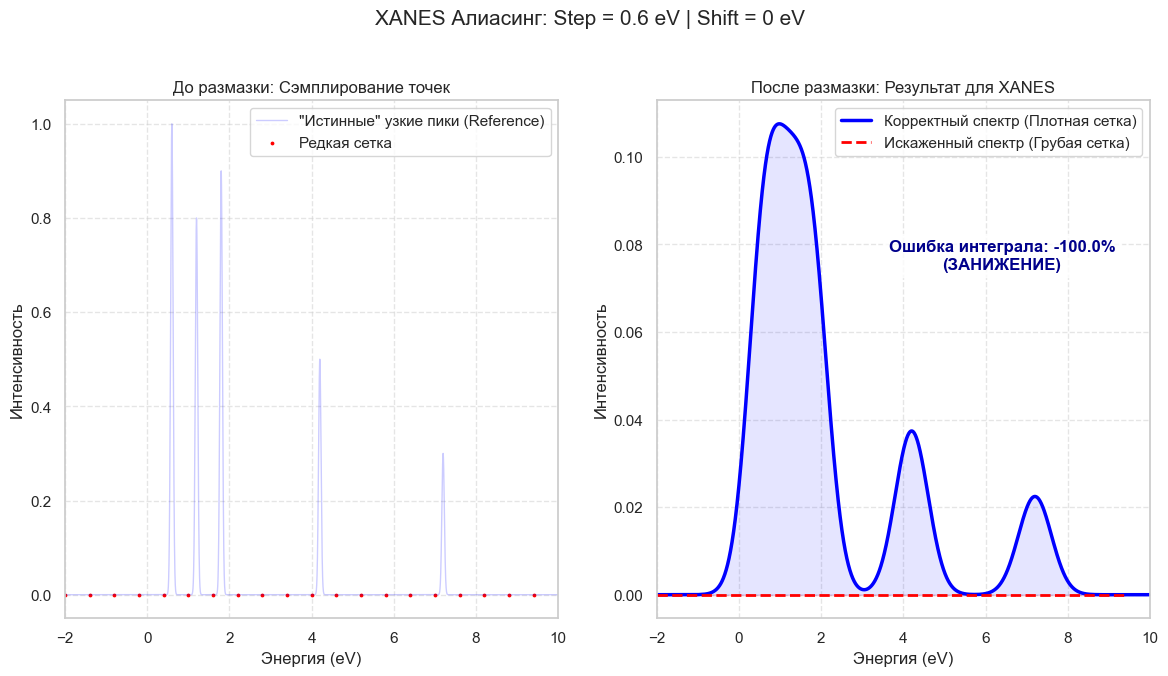

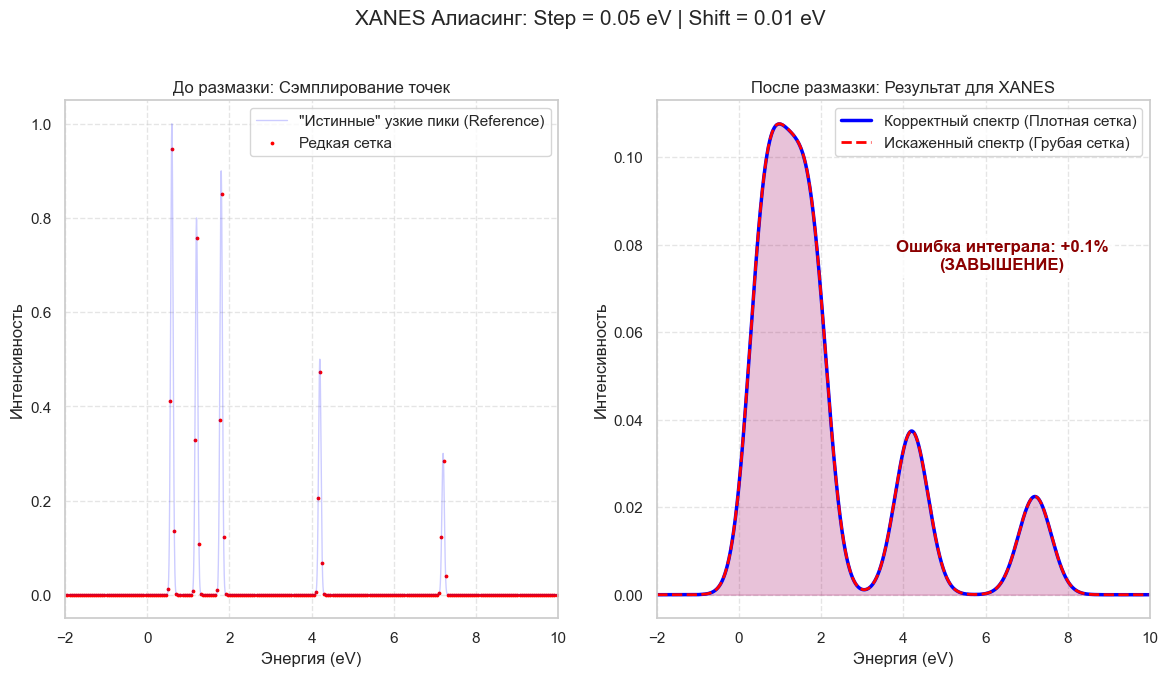

In [14]:
# Попадание в вершины с "средним" шагом. (умеренное завышение)
discretization_influence(step=0.1, shift=0.0, save_path='../images/XANES_Aliasing_st_0.1_sh_0.png')

# Попадание в середины с "средним" шагом. (умеренное занижение)
discretization_influence(step=0.1, shift=0.05, save_path='../images/XANES_Aliasing_st_0.1_sh_0.05.png')

# Попадание в вершины с "большим" шагом. (чрезмерное завышение)
discretization_influence(step=0.6, shift=0.2, save_path='../images/XANES_Aliasing_st_0.6_sh_0.2.png')

# Попадание в середины с "большим" шагом. (завышение)
discretization_influence(step=0.6, shift=0.15, save_path='../images/XANES_Aliasing_st_0.6_sh_0.15.png')


# Попадание в мало интенсивные области с "большим" шагом. (чрезмерное занижение)
discretization_influence(step=0.6, shift=0.12, save_path='../images/XANES_Aliasing_st_0.6_sh_0.12.png')


# нулевой спектр
discretization_influence(step=0.6, shift=0, save_path='../images/XANES_Aliasing_st_0.6_sh_0.png')


# Относительно "Безопасный" мелкий шаг (>=3 точек на пик)
discretization_influence(step=0.05, shift=0.01, save_path='../images/XANES_Aliasing_st_0.05_sh_0.01.png')


## Некоторые выводы

In [15]:
# Для качественного описания экспериментально наблюдаемых данных XANES результаты расчета необходимо "размазать" 
# (учет конечности времени остовной дырки и фотоэлектрона а также инструментального разрешения монохроматора)

# При этом при настройке функции размазки возникает некоторый произвол в выборе параметров этой функции.
# Обычно они подбираются таким образом, чтобы теоретическая модель фольги (объемного материала) наилучшим образом 
# описывала экспериментальную фольгу. После этого параметры фиксируются и применяются к остальным объектам.

# Для "большой" частицы (или объемного материала) существует довольно широкая область значений параметров начального уширения 
# вблизи энергии Ферми (E_F), изменения внутри которой не приводят к значительным изменениям в результирующем спектре (из-за гладкости).
# Однако для малых НК, обладающих острыми и высокими пиками, спектр может быть крайне чувствительным к малейшим изменениям этих параметров.

# Т.е. фиксация параметров опираясь только на спектр фольги может исказить физическую картину для малых кластеров.
# Таким образом при генерации данных спектров XANES для НЧ различных размеров необходимо проводить совместную (одновременную) 
# оптимизацию параметров уширения для всех доступных объектов.

# Для реальных НК, поверхностные атомы которых зачастую связываются с кислородом, одним из основных критериев правильности подбора параметров
# может являеться монотонное уменьшение интенсивности белой линии с увеличением размера НК, плавно сходясь к спектру объемного эталона.
# Однако в случае модельных НК находящихся в вакууме (без какого либо окружения НЧ) такая тенденция не обязательно является правильной или достижимой.

# Также важно отметить, что шаг расчетной сетки по энергии (частота дискретизации) в околокраевой области и зоне белой линии должен быть
# достаточно малым (высокая частота), особенно для малых НК. Если шаг расчета будет шире, чем половина периода 
# самой высокочастотной осцилляции в системе, возникнет искажение формы спектра (эффект алиасинга, теорема Котельникова). 
# Для малых НК с их острыми структурными пиками это может быть критично, приводя к непредсказуемым ошибкам при последующей свертке с функцией уширения.